<a href="https://colab.research.google.com/github/FarahGaddour/NutriSnap/blob/main/tp-01-voitures-occasion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 1 — Estimer le prix d'une voiture d'occasion

**Machine Learning · Régression linéaire · TP en classe, sur Colab**

## Le contexte

**Roulez Malin** (un site fictif) publie des annonces de voitures d'occasion entre particuliers.
Quand un vendeur publie son annonce, il ne sait pas quel prix demander. Le site veut lui
**suggérer un prix**, et savoir **de combien cette suggestion peut se tromper**.

## Les données

2 030 annonces **fictives**, fabriquées pour ce TP, avec les défauts d'un vrai fichier.

## Avant de commencer

Faites **Fichier › Enregistrer une copie dans Drive**, et travaillez dans cette copie : sinon,
votre travail ne sera pas sauvegardé.

## Comment travailler

- Chaque étape commence par une courte explication, puis une consigne **À VOUS** : écrivez le
  code dans la cellule vide qui suit, exécutez-la (Maj + Entrée) et lisez le résultat.
- La consigne dit ce qu'il faut obtenir, pas comment : à vous de trouver le code et les
  bibliothèques. Bloqué ? Relisez la présentation, ou demandez.
- Deux cellules sont déjà écrites (le chargement du fichier et le pipeline) : exécutez-les et
  lisez-les.
- Après certains résultats, une cellule de texte **À VOUS** demande une ou deux phrases : ce que
  vous constatez, ce que vous décidez, et pourquoi. Double-cliquez dessus pour écrire.
- Les étapes sont les dix étapes de la présentation.

Ce TP ne se rend pas. Gardez-le : il vous servira de modèle pour le projet.

## 1. Préparer les outils

**À VOUS** : Importez les bibliothèques dont vous aurez besoin : pour manipuler des tableaux de données, faire des calculs, tracer des graphiques, puis découper les données, mesurer une erreur et enregistrer un modèle. Vous pouvez compléter cette cellule au fur et à mesure du TP.

In [16]:
# À VOUS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error
import joblib

## 2. Charger les données

Les données sont lues directement en ligne : exécutez simplement la cellule.

In [17]:
import pandas as pd

brutes = pd.read_csv("https://raw.githubusercontent.com/reda76/ece-ml-tp/main/annonces_voitures_occasion.csv")
print(brutes.shape)
brutes.head()

(2030, 8)


,id_annonce,marque,annee,kilometrage,carburant,boite,puissance_ch,prix_eur
0,100001,Volkswagen,2011,175300,Diesel,Manuelle,130.0,2950
1,100002,Dacia,2017,166900,Diesel,Manuelle,110.0,4450
2,100003,Peugeot,2017,230900,Essence,Automatique,120.0,4400
3,100004,Renault,2024,21700,Électrique,Manuelle,130.0,26500
4,100005,Toyota,2020,93400,Diesel,Manuelle,160.0,12400


| Colonne | Ce qu'elle contient |
|---|---|
| `id_annonce` | Numéro de l'annonce (ne sert pas à prédire) |
| `marque` | Marque de la voiture |
| `annee` | Année de la première mise en circulation |
| `kilometrage` | Kilomètres au compteur |
| `carburant` | Essence, Diesel, Hybride ou Électrique |
| `boite` | Boîte de vitesses : Manuelle ou Automatique |
| `puissance_ch` | Puissance en chevaux |
| `prix_eur` | **Le prix de l'annonce : ce qu'on veut prédire** |

## 3. Inspecter (étape 1)

Avant tout, on regarde ce qui manque et ce qui semble impossible.

**À VOUS** : Pour chaque colonne, affichez combien de valeurs manquent. Puis affichez un résumé statistique des colonnes de nombres : moyenne, minimum, maximum…

In [18]:
# À VOUS
print(brutes.isna().sum())
brutes.describe()

id_annonce        0
marque            0
annee             0
kilometrage       0
carburant         0
boite             0
puissance_ch    142
prix_eur          0
dtype: int64


,id_annonce,annee,kilometrage,puissance_ch,prix_eur
count,2030.000000,2030.000000,2.030000e+03,1888.000000,2030.000000
mean,101015.500000,2017.393103,1.350693e+05,127.219280,10898.030542
std,586.154843,4.593710,3.882787e+05,31.176381,32095.510485
min,100001.000000,2010.000000,5.400000e+03,60.000000,1.000000
25%,100508.250000,2013.000000,5.770000e+04,110.000000,4050.000000
50%,101015.500000,2017.000000,1.093500e+05,120.000000,7350.000000
75%,101522.750000,2021.000000,1.652750e+05,140.000000,13337.500000
max,102030.000000,2025.000000,9.999999e+06,250.000000,999999.000000


**À VOUS** : notez trois choses étranges.

- Il manque des valeurs, surtout dans la colonne puissance.
- Certains prix n’ont pas de sens : il y en a de presque gratuits et d’autres beaucoup trop chers.
- Certains kilométrages sont impossibles, beaucoup trop élevés ou même négatifs.

## 4. Les doublons (étape 2)

Une annonce publiée deux fois compterait double dans l'apprentissage, et ses deux copies
pourraient tomber l'une dans l'apprentissage, l'autre dans le test. On compare les lignes
**sans le numéro d'annonce**, qui change à chaque publication.

**À VOUS** : Comptez les annonces publiées deux fois, en comparant toutes les colonnes **sauf le numéro d'annonce**. Puis créez un nouveau tableau `sans_doublons` qui n'en garde qu'un exemplaire, sans modifier `brutes`, et affichez combien d'annonces il reste.

In [19]:
colonnes = brutes.columns.drop("id_annonce")

print("Doublons :", brutes.duplicated(subset=colonnes).sum())

sans_doublons = brutes.drop_duplicates(subset=colonnes)
print("Annonces restantes :", len(sans_doublons))

Doublons : 30
Annonces restantes : 2000


**À VOUS** : pourquoi supprimer les copies plutôt que les garder ?

Si on garde les copies, une même voiture compte deux fois quand le modèle apprend. Et si une copie se retrouve dans le test, le modèle a déjà vu cette annonce, donc il paraît plus juste qu’il ne l’est vraiment ce qui causera un blocus pour les etapes suivantes du tp

## 5. Le périmètre (étape 3)

Le site veut suggérer un prix pour des voitures ordinaires. Deux règles, écrites à l'avance :
un prix entre 500 € et 150 000 €, et au plus 400 000 km.

**À VOUS** : Créez un tableau `propres` qui ne garde de `sans_doublons` que les annonces dont le prix est entre 500 € et 150 000 €, **et** dont le kilométrage est d'au plus 400 000 km. Affichez combien d'annonces ont été écartées.

In [20]:
# À VOUS
propres = sans_doublons[(sans_doublons["prix_eur"] >= 500) & (sans_doublons["prix_eur"] <= 150000)  & (sans_doublons["kilometrage"] <= 400000)]

print("Annonces écartées", len(sans_doublons) - len(propres))

Annonces écartées 19


**À VOUS** : justifiez chaque règle en une phrase. Que ne saura pas faire le site ?
On garde les prix entre 500 € et 150 000 € : en dessous de 500 €, c’est souvent une erreur  et au-dessus de 150 000 €, ce sont des voitures de luxe, pas des voitures ordinaires
 on regarde aussi les voitures qui ont roulé au plus 400 000 km, parce qu’au-delà c’est sûrement une erreur ou une voiture en fin de vie. Le site ne pourra donc pas donner de prix pour les voitures de luxe ou de collection, les épaves, ni les voitures qui ont énormément roulée


## 6. Explorer (étape 4)

Deux graphiques, chacun pour une question : le prix baisse-t-il avec l'âge ? La marque
compte-t-elle ?

**À VOUS** : Faites deux graphiques, chacun avec un titre : le prix selon l'année (un point par annonce), et le prix médian de chaque marque (en barres).

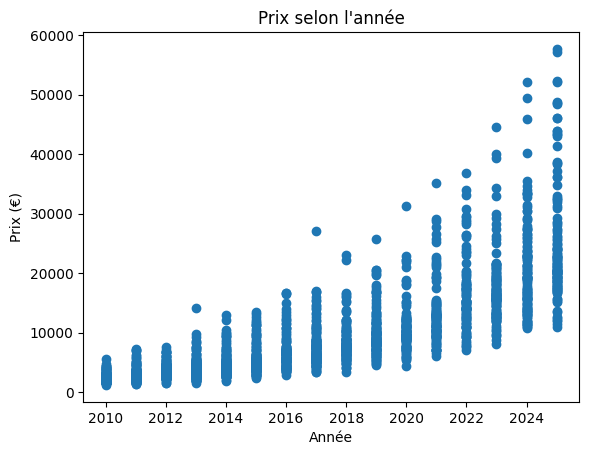

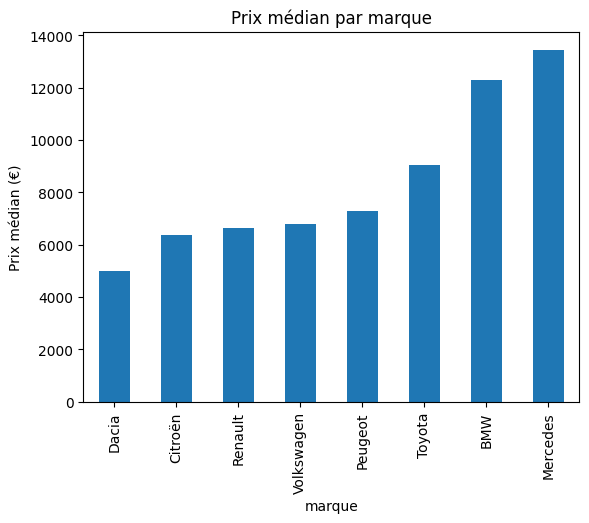

In [21]:
plt.scatter(propres["annee"], propres["prix_eur"])
plt.title("Prix selon l'année")
plt.xlabel("Année")
plt.ylabel("Prix (€)")
plt.show()

propres.groupby("marque")["prix_eur"].median().sort_values().plot(kind="bar")
plt.title("Prix médian par marque")
plt.ylabel("Prix médian (€)")
plt.show()

**À VOUS** : que montre chaque graphique, en une phrase ?
Le premier graphique montre que plus la voiture est récente, plus elle est chère. Le deuxième montre que la marque compte : une Mercedes ou une BMW coûte plus de deux fois plus cher qu’une Dacia.


## 7. Séparer (étape 5)

On met 20 % des annonces **au coffre** : le modèle ne les verra jamais pendant sa construction.
Elles serviront une seule fois, à la fin, à mesurer la version retenue.

**À VOUS** : Préparez `X`, les colonnes qui décrivent la voiture (tout sauf le numéro d'annonce et le prix), et `y`, le prix. Puis mettez 20 % des annonces de côté pour le test, avec un tirage reproductible (`random_state=42`). Nommez les quatre morceaux `X_appr`, `X_test`, `y_appr` et `y_test`.

In [22]:
# À VOUS
X = propres.drop(columns=["id_annonce", "prix_eur"])
y = propres["prix_eur"]

X_appr, X_test, y_appr, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_appr.shape, X_test.shape)

(1584, 6) (397, 6)


## 8. La référence (étape 6)

Sans aucun modèle, le site pourrait suggérer à tout le monde le même prix : le prix médian.
Son erreur est le **seuil à battre**.

**À VOUS** : Calculez le prix médian des annonces d'apprentissage. Puis calculez l'erreur moyenne qu'on ferait en suggérant ce même prix à **toutes** les annonces du test. Gardez-la dans une variable `erreur_reference` et affichez-la en euros.

In [23]:
# À VOUS
mediane = y_appr.median()
erreur_reference = mean_absolute_error(y_test, np.full(len(y_test), mediane))
print(f"Prix médian (apprentissage) : {mediane:,.0f} €")
print(f"Erreur de référence : {erreur_reference:,.0f} €")

Prix médian (apprentissage) : 7,300 €
Erreur de référence : 5,412 €


## 9. Le pipeline (étape 7)

Le pipeline enchaîne la préparation et le modèle dans un seul objet :

| Pour | Préparation |
|---|---|
| les nombres | remplir les valeurs manquantes par la médiane, puis normaliser |
| les catégories | une colonne 0/1 par valeur (encodage) |
| tout | la régression linéaire |

Tout ce que la préparation apprend (médianes, échelles, liste des marques) est appris sur les
données d'apprentissage, puis figé.

In [25]:
from sklearn.model_selection import cross_val_score

VERSIONS = {
    "V1": (["annee"], []),
    "V2": (["annee", "kilometrage"], []),
    "V3": (["annee", "kilometrage", "puissance_ch"], ["carburant", "boite"]),
    "V4": (["annee", "kilometrage", "puissance_ch"], ["carburant", "boite", "marque"]),
}

resultats = []
for nom, (nombres, categories) in VERSIONS.items():
    pipe = fabriquer_pipeline(nombres, categories)
    scores = cross_val_score(pipe, X_appr[nombres + categories], y_appr,
                             cv=5, scoring="neg_mean_absolute_error")
    erreurs = -scores
    resultats.append({"version": nom,
                      "erreur moyenne": round(erreurs.mean()),
                      "variation": round(erreurs.std())})

pd.DataFrame(resultats)

,version,erreur moyenne,variation
0,V1,3416,83
1,V2,3367,90
2,V3,2709,94
3,V4,2478,73


## 10. Les versions (étape 8)

On part simple et on ajoute **une chose à la fois**. Chaque version est mesurée par
**validation croisée** sur les données d'apprentissage : 5 découpages, 5 erreurs. Leur moyenne
est l'erreur de la version ; leur variation dit ce que le hasard du découpage peut faire bouger.
Le coffre reste fermé.

**À VOUS** : Les quatre versions sont données. Pour chacune, mesurez l'erreur moyenne par validation croisée en 5 parts, sur les seules données d'apprentissage, avec le pipeline de l'étape 9. Rassemblez, dans un tableau, l'erreur moyenne et la variation (l'écart-type) de chaque version.

In [26]:
VERSIONS = {
    "V1": (["annee"], []),
    "V2": (["annee", "kilometrage"], []),
    "V3": (["annee", "kilometrage", "puissance_ch"], ["carburant", "boite"]),
    "V4": (["annee", "kilometrage", "puissance_ch"], ["carburant", "boite", "marque"]),
}
# À VOUS : pour chaque version, la validation croisée, puis un tableau des résultats


**À VOUS** : quel gain apporte chaque ajout ? Est-il plus grand que la variation ? Quelle version retenez-vous ?
Ajouter le kilométrage ne fait gagner que 49 €, moins que la variation (environ 90 €), donc ce gain peut venir du hasard. Ajouter la puissance, le carburant et la boîte fait gagner 658 €, c’est le plus gros gain. Ajouter la marque fait encore gagner 231 €, plus que la variation. Je retiens la V4, qui se trompe le moins (2 478 €).

## 11. Mesurer la version retenue (fin de l'étape 8)

On ouvre le coffre, **une seule fois**, pour mesurer la version retenue sur des annonces
qu'elle n'a jamais vues.

**À VOUS** : Entraînez le pipeline de la version que vous retenez sur toutes les données d'apprentissage, et appelez-le `modele`. Puis mesurez son erreur sur le test, **une seule fois**, et comparez-la à `erreur_reference`.

In [27]:
from sklearn.metrics import mean_absolute_error

RETENUE = "V4"
nombres, categories = VERSIONS[RETENUE]
colonnes = nombres + categories

modele = fabriquer_pipeline(nombres, categories)
modele.fit(X_appr[colonnes], y_appr)

erreur_test = mean_absolute_error(y_test, modele.predict(X_test[colonnes]))
print("Erreur du modèle :", round(erreur_test), "€")
print("Erreur de référence :", round(erreur_reference), "€")

Erreur du modèle : 2439 €
Erreur de référence : 5412 €


## 12. Interpréter (étape 9)

Un modèle se lit. On prend une voiture, on change **une seule chose**, et on regarde comment
le prix suggéré bouge.

**À VOUS** : Voici une voiture. Affichez le prix que `modele` lui suggère. Puis changez **une seule chose** à la fois (l'année à 2017, le kilométrage à 110 000 km, la boîte en automatique) et affichez à chaque fois l'écart de prix.

In [28]:
voiture = pd.DataFrame([{"annee": 2018, "kilometrage": 90_000, "puissance_ch": 110,
                         "carburant": "Essence", "boite": "Manuelle", "marque": "Peugeot"}])

prix = modele.predict(voiture)[0]
print("Prix suggéré :", round(prix), "€")

v = voiture.copy()
v["annee"] = 2017
print("Année 2017 :", round(modele.predict(v)[0] - prix), "€")

v = voiture.copy()
v["kilometrage"] = 110_000
print("110 000 km :", round(modele.predict(v)[0] - prix), "€")

v = voiture.copy()
v["boite"] = "Automatique"
print("Automatique :", round(modele.predict(v)[0] - prix), "€")

Prix suggéré : 8644 €
Année 2017 : -1151 €
110 000 km : -297 €
Automatique : 891 €


**À VOUS** : Affichez les 5 annonces du test où le modèle se trompe le plus, avec pour chacune le vrai prix, le prix suggéré et l'écart entre les deux.

In [30]:
# À VOUS
tableau = pd.DataFrame()
tableau["vrai prix"] = y_test
tableau["prix suggéré"] = modele.predict(X_test)
tableau["écart"] = abs(tableau["vrai prix"] - tableau["prix suggéré"])

tableau.sort_values("écart", ascending=False).head(5)

,vrai prix,prix suggéré,écart
539,48700,28987.773514,19712.226486
1378,43400,25398.202207,18001.797793
1690,41300,27317.647935,13982.352065
816,34900,23034.920759,11865.079241
1138,36150,24324.509362,11825.490638


**À VOUS** : que vaut un an de plus, en euros ? Qu'ont en commun les plus grosses erreurs ?

## 13. Livrer (étape 10)

Le site ne refait pas tout ce notebook à chaque annonce : on enregistre le pipeline dans un
fichier, et le site le recharge. Le pipeline prépare tout seul une annonce brute, même avec une
valeur manquante.

**À VOUS** : Enregistrez `modele` dans un fichier, rechargez-le comme le ferait le site, puis suggérez un prix pour l'annonce ci-dessous, dont la puissance est inconnue.

In [29]:
import joblib

joblib.dump(modele, "modele.joblib")
modele_site = joblib.load("modele.joblib")

annonce = pd.DataFrame([{"annee": 2019, "kilometrage": 80_000, "puissance_ch": None,
                         "carburant": "Diesel", "boite": "Manuelle", "marque": "Renault"}])

print("Prix suggéré :", round(modele_site.predict(annonce)[0]), "€")

Prix suggéré : 10912 €


## 14. Conclusion pour Roulez Malin

**À VOUS** : en quatre ou cinq phrases, sans jargon : de combien se trompe la suggestion,
comparée à la référence ? Le site peut-il l'afficher, et comment la présenter ? Quelles sont ses
limites ?

Sans modèle, si on propose le même prix à tout le monde, on se trompe en moyenne de 5 412 €. Avec notre modèle, on se trompe en moyenne de 2 439 €, soit plus de deux fois moins. Le site peut donc afficher le prix suggéré, mais plutôt comme une fourchette d’environ 2 400 € de chaque côté, par exemple « entre 7 600 et 12 400 € » pour un prix suggéré de 10 000 €. Le modèle marche seulement pour les voitures normales, pas pour les voitures de luxe, les épaves ou celles qui ont énormément roulé. Il ne connaît pas non plus l’état de la voiture, donc le vendeur doit garder le dernier mot.